# Ejercicio Final de comparación del comportamiento de los modelos

## Librerías y configuración

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report
)

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier

In [39]:
#Plantilla de construcción de conjunto de pruebas y testeo

df = pd.read_csv("./data/df_final.csv")

numeric_features = [
    "age",
    "baseline_bmi",
    "baseline_charlson_comorbidity_index",
    "length_of_stay_days",
    "icu_days",
    "news2_acuity_score",
    "revisit_count",
    "n_meds",
    "n_high_risk_meds",
    "serum_creatinine_mg_dl",
    "hemoglobin_g_dl",
    "spo2_percent",
    "respiratory_rate_bpm",
    "heart_rate_bpm",
    "systolic_bp_mmhg",
    "white_blood_cell_count",
    "blood_glucose_mg_dl"
]

categoric_features = [
    "discharge_disposition",
    "disease_category",
    "disease_severity",
    "department",
    "admission_urgency",
    "encounter_type",
    "primary_insurance_provider",
    "socioeconomic_tier",
    "residential_zone",
    "smoker_status",
    "gender",
    "procedure_complexity",
    "hospital_acquired_infection"   
]

y = df["readmission_30d"].copy()
X = df[numeric_features + categoric_features]

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")



X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          
    random_state=42,         
    stratify=y              
)


preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoric_features)
    ],
    remainder="drop"
)



X shape: (13214, 30)
y shape: (13214,)


In [40]:
#Objeto de modelos a entrenar
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
modelos = {
    "Línea Base": DummyClassifier(strategy="most_frequent", random_state=42),
    
    "Regresión Logística": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    
    "KNN (k=15)":KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    
    "Árbol de Decisión": DecisionTreeClassifier(
        max_depth=4,          
        random_state=42,
        class_weight="balanced"  
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    ),
    
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=15,
        subsample=0.8,
        max_features="sqrt",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),  
    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=42
    ),

    "Red Neuronal": MLPClassifier(
        hidden_layer_sizes=(32, 16),  # dos capas ocultas
        activation="relu",
        solver="adam",                # variante del descenso de gradiente
        learning_rate_init=0.001,     # la "tasa de aprendizaje" de las diapositivas
        alpha=1e-3,                   # regularización L2
        early_stopping=True,          # frena cuando deja de mejorar en validación
        max_iter=500,
        random_state=42
    )
}



In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

resultados = []
modelos_entrenados = {}

for nombre, clf in modelos.items():
    print(f"\nEntrenando: {nombre}")
    
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    
    cv_results = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring,
        n_jobs=-1, return_train_score=False
    )
    
    pipe.fit(X_train, y_train)
    
  
    y_pred = pipe.predict(X_test)
    
    try:
        y_proba = pipe.predict_proba(X_test)[:, 1]
        auc_test = roc_auc_score(y_test, y_proba)
    except:
        auc_test = np.nan
    
    fila = {
        "Modelo": nombre,
        "Accuracy_CV": cv_results["test_accuracy"].mean(),
        "Precision_CV": cv_results["test_precision"].mean(),
        "Recall_CV": cv_results["test_recall"].mean(),
        "F1_CV": cv_results["test_f1"].mean(),
        "AUC_CV": cv_results["test_roc_auc"].mean(),
        "Accuracy_Test": accuracy_score(y_test, y_pred),
        "Precision_Test": precision_score(y_test, y_pred, zero_division=0),
        "Recall_Test": recall_score(y_test, y_pred, zero_division=0),
        "F1_Test": f1_score(y_test, y_pred, zero_division=0),
        "AUC_Test": auc_test
    }
    resultados.append(fila)
    
    modelos_entrenados[nombre] = pipe


Entrenando: Línea Base

Entrenando: Regresión Logística

Entrenando: KNN (k=15)

Entrenando: Árbol de Decisión

Entrenando: Random Forest

Entrenando: Gradient Boosting

Entrenando: XGBoost

Entrenando: SVM

Entrenando: Red Neuronal


In [42]:
df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.sort_values("AUC_Test", ascending=False).reset_index(drop=True)

display(df_resultados.round(4))

,Modelo,Accuracy_CV,Precision_CV,Recall_CV,F1_CV,AUC_CV,Accuracy_Test,Precision_Test,Recall_Test,F1_Test,AUC_Test
0,Gradient Boosting,0.7471,0.6663,0.4692,0.5505,0.7948,0.7442,0.6607,0.4639,0.5451,0.7926
1,XGBoost,0.7111,0.5483,0.7144,0.6203,0.7877,0.6992,0.5326,0.7297,0.6158,0.7871
2,Random Forest,0.7332,0.6496,0.4171,0.5078,0.7765,0.7317,0.6464,0.4147,0.5052,0.7854
3,Regresión Logística,0.7295,0.6323,0.4325,0.5136,0.7733,0.7287,0.6309,0.4307,0.5119,0.7767
4,Árbol de Decisión,0.7130,0.5570,0.6580,0.6021,0.7724,0.7162,0.5623,0.6357,0.5968,0.7749
5,Red Neuronal,0.7220,0.6129,0.4308,0.5056,0.7678,0.7200,0.5900,0.4994,0.5409,0.7665
6,KNN (k=15),0.7051,0.5914,0.3460,0.4365,0.6992,0.7007,0.5807,0.3379,0.4272,0.7149
7,Línea Base,0.6698,0.0000,0.0000,0.0000,0.5000,0.6697,0.0000,0.0000,0.0000,0.5000
8,SVM,0.6869,0.5190,0.7184,0.6025,0.7608,0.6829,0.5140,0.7365,0.6055,NaN


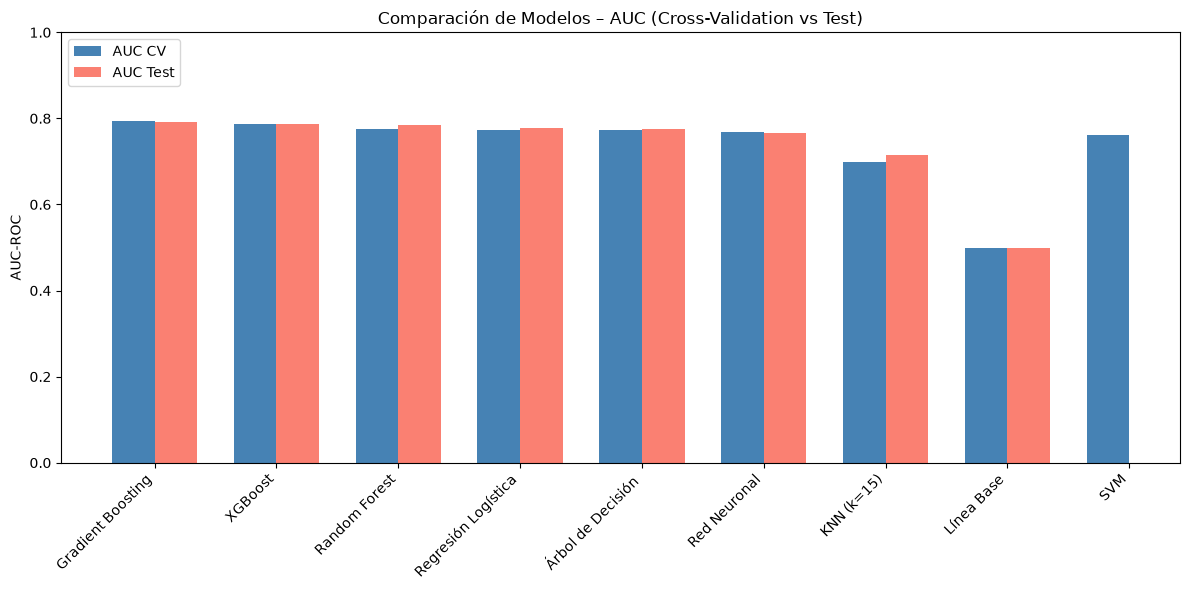

In [43]:
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(df_resultados))
width = 0.35

ax.bar(x - width/2, df_resultados["AUC_CV"], width, label="AUC CV", color="steelblue")
ax.bar(x + width/2, df_resultados["AUC_Test"], width, label="AUC Test", color="salmon")

ax.set_ylabel("AUC-ROC")
ax.set_title("Comparación de Modelos – AUC (Cross-Validation vs Test)")
ax.set_xticks(x)
ax.set_xticklabels(df_resultados["Modelo"], rotation=45, ha="right")
ax.legend()
ax.set_ylim(0, 1.0)
plt.tight_layout()
plt.show()

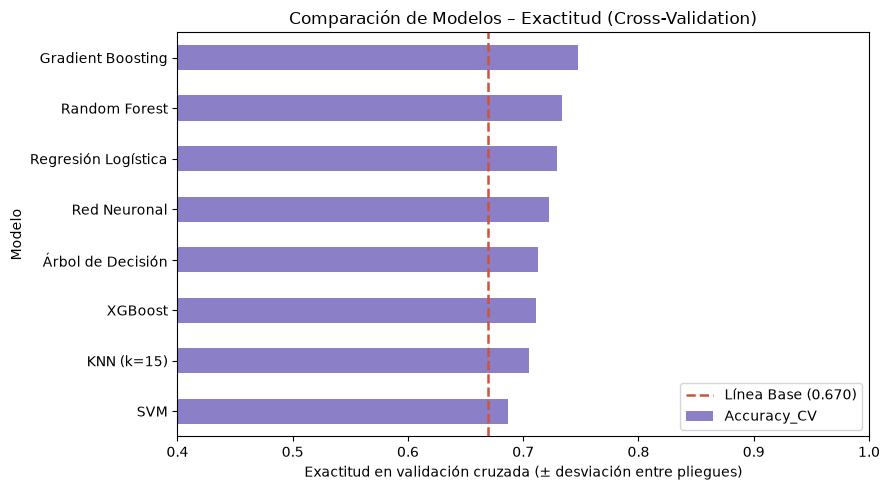

Top modelos por Exactitud CV:
                Modelo  Accuracy_CV  AUC_CV  F1_CV
0    Gradient Boosting        0.747   0.795  0.551
2        Random Forest        0.733   0.777  0.508
3  Regresión Logística        0.730   0.773  0.514
5         Red Neuronal        0.722   0.768  0.506
4    Árbol de Decisión        0.713   0.772  0.602


In [44]:
orden = (
    df_resultados[df_resultados["Modelo"] != "Línea Base"]
    .sort_values("Accuracy_CV")
    .set_index("Modelo")
)

linea_base_acc = df_resultados.loc[
    df_resultados["Modelo"] == "Línea Base", "Accuracy_CV"
].values[0]


fig, ax = plt.subplots(figsize=(9, 5))

orden["Accuracy_CV"].plot.barh(
    xerr=orden.get("Accuracy_CV_std", 0),   
    color="#8B7FC7",
    ax=ax,
    xlim=(0.4, 1)                       
)


ax.axvline(linea_base_acc, color="#C8553D", ls="--", linewidth=1.8, 
           label=f"Línea Base ({linea_base_acc:.3f})")

ax.set_xlabel("Exactitud en validación cruzada (± desviación entre pliegues)")
ax.set_title("Comparación de Modelos – Exactitud (Cross-Validation)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


print("Top modelos por Exactitud CV:")
print(
    df_resultados[df_resultados["Modelo"] != "Línea Base"]
    .sort_values("Accuracy_CV", ascending=False)
    [["Modelo", "Accuracy_CV", "AUC_CV", "F1_CV"]]
    .head(5)
    .round(3)
)

# Conclusión

- A pesar de que todos los modelos entrenados superan la línea base, como equipo nos iríamos por los siguientes dos modelos:

XGBoost: Es el modelo principalmente elegido por el equipo porque aunque no tiene el AUC_Test y accuracy mas alto de todos, cuenta con una buena métrica de Recall que nos indica la capacidad del modelo para reconocer los casos de la clase minoritaria y que para el caso del hospital se adapta mucho para tomar mejores decisiones al momento de atender pacientes hospitalizados.

Random Forest: Teniendo en cuenta que este modelo se entrenó comparándose con la red neuronal se elige porque a pesar de que en su estructura "es mas sencillo" tiene un mejor comportamiento que el de la NN